# 03 · Features and model selection

With the data understood (01) and head pose handled (02), two choices remain: which **features**
and which **regressor**. Everything is evaluated with cross-validation **grouped by person**,
and models are judged not only on accuracy but also on how they behave on faces of people they
have never seen.

1. Feature configurations: landmark set × scale reference
2. Regularisation paths: PLS components and ridge penalty
3. Regressors: PLS, ridge and kernel ridge, in CV and leave-one-database-out, plus jitter
4. Behavioural tests on unseen people: why the less accurate linear model is the default

To keep the runtime to about 5 minutes, this notebook uses 3-fold CV on the original images (no
mirrored copies) and every second morph step (adjacent steps of the same morph are
near-duplicates). The full analyses (5-fold, repeats, nested CV, more models) are
`experiments/05`, `06`, `08` and `12`. They give the same conclusions, at slightly higher CCC
because they train on more data.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
ROOT = Path.cwd() if (Path.cwd() / "examples").is_dir() else Path.cwd().parent  # repo root

from IPython.display import display
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from facial_expression_analysis import Frontalizer, KernelEmotionModel, LinearEmotionModel
from facial_expression_analysis.features import PairwiseDistanceFeatures
from facial_expression_analysis.training.data import load_morphset
from facial_expression_analysis.training.evaluation import (
    pls_path,
    repeated_group_kfold,
    ridge_path,
)
from facial_expression_analysis.training.frontalization import load_pose_dataset
from facial_expression_analysis.training.metrics import ccc

TARGETS = ("arousal", "valence", "intensity")


def cccs(y, p):
    return [ccc(y[:, k], p[:, k]) for k in range(3)]

In [2]:
data = load_morphset()
step = data.meta.filename.str.split("_").str[-2]
orig = (
    ~data.meta.mirrored & ((data.meta.label == "NE") | step.isin(["2", "4", "6", "8", "10"]))
).to_numpy()
landmarks, y = data.landmarks[orig], data.targets[orig]
persons = data.persons[orig]
databases = data.meta.dataset.astype(str).to_numpy()[orig]
frontal = Frontalizer()(landmarks)
folds = repeated_group_kfold(persons, n_splits=3, seed=0)
print(
    f"{len(y):,} faces of {len(set(persons))} persons; folds of {[len(f.test) for f in folds]} test faces"
)

41,951 faces of 337 persons; folds of [14524, 14056, 13371] test faces


## 1. Feature configurations

All variants are pairwise Euclidean distances between landmarks of the frontalized shape,
divided by a face scale. They differ in which landmarks are used and which landmarks define
the scale. PLS(31) throughout.

In [3]:
%%time
configs = {
    "2021 template (bug: pairs 0-50)": PairwiseDistanceFeatures(
        landmark_indices=np.arange(51), scale=np.arange(17, 68)
    ),
    "51 non-jaw, stable scale (default)": PairwiseDistanceFeatures("no_jaw", scale="stable"),
    "51 non-jaw, subset scale": PairwiseDistanceFeatures("no_jaw", scale="subset"),
    "all 68, stable scale": PairwiseDistanceFeatures("all", scale="stable"),
}
feature_scores = {}
for name, feat in configs.items():
    X = feat(frontal)
    feature_scores[name] = np.array(
        [
            cccs(y[f.test], pls_path(X[f.train], y[f.train], 31).predict(X[f.test])[-1])
            for f in folds
        ]
    )
table = pd.DataFrame({name: s.mean(0) for name, s in feature_scores.items()}, index=TARGETS).T
table["features"] = [configs[n].n_features for n in table.index]
table

CPU times: user 3min 30s, sys: 2.46 s, total: 3min 32s
Wall time: 3min 32s


,arousal,valence,intensity,features
2021 template (bug: pairs 0-50),0.625,0.814,0.666,1275
"51 non-jaw, stable scale (default)",0.645,0.821,0.682,1275
"51 non-jaw, subset scale",0.653,0.821,0.682,1275
"all 68, stable scale",0.637,0.819,0.676,2278


In [4]:
base = feature_scores["51 non-jaw, stable scale (default)"]
diff = pd.DataFrame(
    {name: (s - base).mean(0) for name, s in feature_scores.items() if s is not base}, index=TARGETS
).T
diff["better in folds (A/V/I)"] = [
    "/".join(str(int(v)) for v in ((s - base) > 0).sum(0))
    for n, s in feature_scores.items()
    if s is not base
]
print("CCC difference vs the default (positive = better than default), paired by fold")
diff.round(3)

CCC difference vs the default (positive = better than default), paired by fold


,arousal,valence,intensity,better in folds (A/V/I)
2021 template (bug: pairs 0-50),-0.021,-0.007,-0.016,0/0/0
"51 non-jaw, subset scale",0.008,0.000,0.001,3/2/2
"all 68, stable scale",-0.009,-0.002,-0.006,0/1/0


- **The 2021 template bug is the largest effect**: it silently used the jaw and dropped most mouth
  landmarks, losing about 0.02 CCC in every fold.
- **Jaw**: adding it costs intensity accuracy (jaw landmarks are the noisiest part of a dlib fit).
- **49 vs 51 points** (IntraFace scheme, not run here): a tie in `experiments/05`.
- **Scale**: the stable scale costs a little arousal compared with the subset scale. The scale
  inflation from notebook 01 was itself a weak arousal cue. The stable scale is kept because
  each feature then responds only to its own two landmarks, which makes the model interpretable
  and robust.

## 2. How many PLS components? How much ridge penalty?

PLS components and ridge penalties form regularisation paths; one fit gives every member.

PLS mean CCC at k=31: 0.716; best k=50: 0.742
CPU times: user 56.6 s, sys: 458 ms, total: 57.1 s
Wall time: 56.7 s


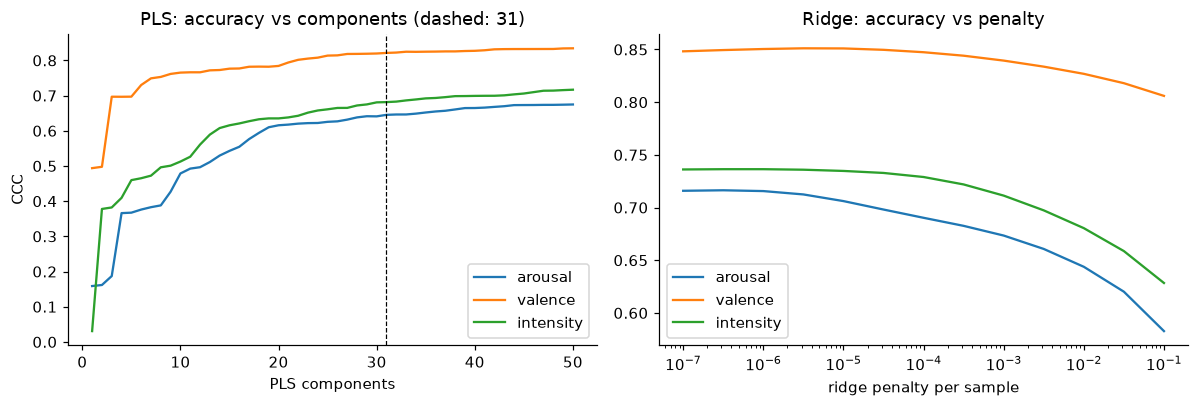

In [5]:
%%time
X = configs["51 non-jaw, stable scale (default)"](frontal)
alphas = np.logspace(-7, -1, 13)
pls_curve, ridge_curve = [], []
for f in folds:
    for k, p in enumerate(pls_path(X[f.train], y[f.train], 50).predict(X[f.test]), start=1):
        pls_curve.append([k, *cccs(y[f.test], p)])
    for a, p in zip(
        alphas, ridge_path(X[f.train], y[f.train], alphas).predict(X[f.test]), strict=True
    ):
        ridge_curve.append([a, *cccs(y[f.test], p)])
pls_curve = pd.DataFrame(pls_curve, columns=["k", *TARGETS]).groupby("k").mean()
ridge_curve = pd.DataFrame(ridge_curve, columns=["alpha", *TARGETS]).groupby("alpha").mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
pls_curve.plot(ax=axes[0])
axes[0].axvline(31, color="k", ls="--", lw=0.8)
axes[0].set(xlabel="PLS components", ylabel="CCC", title="PLS: accuracy vs components (dashed: 31)")
ridge_curve.plot(ax=axes[1], logx=True)
axes[1].set(xlabel="ridge penalty per sample", title="Ridge: accuracy vs penalty")
plt.tight_layout()
best_k = pls_curve.mean(axis=1).idxmax()
print(
    f"PLS mean CCC at k=31: {pls_curve.loc[31].mean():.3f}; best k={best_k}: {pls_curve.mean(axis=1).max():.3f}"
)

Accuracy rises steeply up to about 20 components and keeps creeping up beyond 31 (nested CV in
`experiments/06` picks about 50 by the one-standard-error rule). Ridge prefers little
regularisation: with tens of thousands of faces, 1,275 features are not many. 31 components was
the 2021 choice, roughly the number of facial action units. Section 4 shows why more accuracy is
not the deciding criterion.

## 3. Regressors: accuracy, generalisation to a new database, jitter

- **PLS(31)**: linear, low-rank.
- **Ridge**: linear, full-rank; penalty from `experiments/06`.
- **Kernel ridge**: RBF kernel on a 2,000-face Nyström basis (γ = 0.5/1,275, α = 1, from
  nested CV).

Schemes: the 3 person-grouped folds, then **leave one database out**, where the model never sees
any face from that database. Jitter: 1 px Gaussian noise per landmark coordinate (dlib's
repeatability, notebook 01) on 2,000 test faces, mean |ΔA| and |ΔV|.

In [6]:
%%time


def kernel_ridge():
    return make_pipeline(
        StandardScaler(),
        Nystroem(gamma=0.5 / X.shape[1], n_components=2000, random_state=0),
        Ridge(alpha=1.0),
    )


models = {
    "PLS(31)": lambda Xtr, ytr: pls_path(Xtr, ytr, 31),
    "ridge": lambda Xtr, ytr: ridge_path(Xtr, ytr, [2.5e-5]),
    "kernel ridge": lambda Xtr, ytr: kernel_ridge().fit(Xtr.astype(np.float64), ytr),
}


def predict(model, Xte):
    return (
        model.predict(Xte)[-1]
        if hasattr(model, "params")
        else model.predict(Xte.astype(np.float64))
    )


schemes = [(f"cv fold {f.fold}", f.train, f.test) for f in folds]
schemes += [
    (f"leave out {d}", np.flatnonzero(databases != d), np.flatnonzero(databases == d))
    for d in ("R", "K", "W", "F")
]
rows, jitter = [], []
rng = np.random.default_rng(0)
feat = configs["51 non-jaw, stable scale (default)"]
for scheme, tr, te in schemes:
    for name, fit in models.items():
        model = fit(X[tr], y[tr])
        pred = predict(model, X[te])
        rows.append(
            {"scheme": scheme, "model": name, **dict(zip(TARGETS, cccs(y[te], pred), strict=True))}
        )
        if scheme == "cv fold 0":
            sub = rng.choice(te, 2000, replace=False)
            clean = predict(model, X[sub])[:, :2]
            noisy = predict(
                model,
                feat(Frontalizer()(landmarks[sub] + rng.normal(0, 1.0, landmarks[sub].shape))),
            )[:, :2]
            jitter.append(
                {
                    "model": name,
                    "jitter |ΔA|": np.abs(noisy - clean)[:, 0].mean(),
                    "jitter |ΔV|": np.abs(noisy - clean)[:, 1].mean(),
                }
            )
scores = pd.DataFrame(rows)
scores["kind"] = np.where(
    scores.scheme.str.startswith("cv"), "3-fold CV by person", "leave one database out"
)
summary = scores.groupby(["kind", "model"])[list(TARGETS)].mean().unstack("kind").swaplevel(axis=1)
summary = summary[
    [(k, t) for k in ("3-fold CV by person", "leave one database out") for t in TARGETS]
]
print("CCC (mean over folds / held-out databases)")
display(summary.round(3))
print("Jitter under 1 px landmark noise (fold 0)")
pd.DataFrame(jitter).set_index("model").round(3)

CCC (mean over folds / held-out databases)


kind         3-fold CV by person                   leave one database out  \
                         arousal valence intensity                arousal   
model                                                                       
PLS(31)                    0.645   0.821     0.682                  0.638   
kernel ridge               0.726   0.858     0.729                  0.705   
ridge                      0.700   0.850     0.733                  0.676   

kind                            
             valence intensity  
model                           
PLS(31)        0.790     0.623  
kernel ridge   0.818     0.681  
ridge          0.814     0.688

Jitter under 1 px landmark noise (fold 0)
CPU times: user 1min 38s, sys: 1 s, total: 1min 39s
Wall time: 1min 38s


,jitter |ΔA|,jitter |ΔV|
model,,
PLS(31),0.053,0.093
ridge,0.076,0.115
kernel ridge,0.051,0.059


Kernel ridge is the most accurate on arousal and valence, both within MorphSet and on a held-out
database; full-rank ridge matches it on intensity. Kernel ridge also jitters least, and ridge the
most. PLS(31) is the least accurate of the three. On these numbers alone, kernel ridge would win.

## 4. Behavioural tests on unseen people

The live demo exposed something CCC does not measure. On new faces, the kernel model's resting
point and its response to a smile depend on the person. Three tests on 2,294 frontal neutral
faces of Multi-PIE and CAS-PEAL persons (not in MorphSet), using the two bundled models:

- **A. Neutral calibration:** how far from (0, 0) does a neutral face land?
- **B. Decomposition:** apply a pure lip-corner pull (a synthetic smile, nothing else moves).
  Valence should rise and arousal should not; we count paths more than 20° off the valence axis.
- **C. Pose stability:** spread of the prediction across head yaw, for the same person and
  expression.

In [7]:
SMILE = {
    48: (1.0, -1),
    54: (1.0, 1),
    60: (0.8, -1),
    64: (0.8, 1),
    49: (0.4, -1),
    59: (0.4, -1),
    53: (0.4, 1),
    55: (0.4, 1),
}


def synthetic_smile(lm, strength):
    out = lm.copy()
    eye = np.linalg.norm(lm[:, 36:42].mean(1) - lm[:, 42:48].mean(1), axis=1)
    for i, (w, side) in SMILE.items():
        out[:, i, 0] += side * w * strength * 0.07 * eye
        out[:, i, 1] -= w * strength * 0.08 * eye
    return out


pose = load_pose_dataset()
pm = pose.meta.reset_index(drop=True)
unseen = (pm.family != "kdef") & (pm.pitch == 0) & (pm.yaw.abs() <= 45)
neutral = np.flatnonzero(unseen & (pm.expression == "NE") & (pm.yaw == 0))
front = Frontalizer()
results, paths = {}, {}
for name, model in {
    "PLS(31)": LinearEmotionModel.load(),
    "kernel ridge": KernelEmotionModel.load(),
}.items():
    p0 = np.clip(model.predict(front(pose.landmarks[neutral]))[:, :2], -1, 1)
    traj = np.stack(
        [
            model.predict(front(synthetic_smile(pose.landmarks[neutral], s)))[:, :2]
            for s in np.linspace(0, 1, 7)
        ]
    )
    d = traj[-1] - traj[0]
    idx = np.flatnonzero(unseen)
    pred = np.clip(model.predict(front(pose.landmarks[idx]))[:, :2], -1, 1)
    spread = (
        pm.iloc[idx]
        .assign(A=pred[:, 0], V=pred[:, 1])
        .groupby(["subject", "expression"])[["A", "V"]]
        .std()
    )
    paths[name] = traj
    results[name] = {
        "A. neutral: distance from (0,0)": np.hypot(*p0.T).mean(),
        "B. smile: ΔV": d[:, 1].mean(),
        "B. smile: ΔA": d[:, 0].mean(),
        "B. paths > 20° off the valence axis": (
            np.abs(np.degrees(np.arctan2(d[:, 0], d[:, 1]))) > 20
        ).mean(),
        "C. pose: std of A across yaw": spread.A.mean(),
        "C. pose: std of V across yaw": spread.V.mean(),
    }
print(f"{len(neutral)} neutral frontal faces of unseen people")
pd.DataFrame(results).round(3)

2294 neutral frontal faces of unseen people


,PLS(31),kernel ridge
"A. neutral: distance from (0,0)",0.222,0.339
B. smile: ΔV,0.336,0.400
B. smile: ΔA,-0.007,0.040
B. paths > 20° off the valence axis,0.001,0.207
C. pose: std of A across yaw,0.075,0.091
C. pose: std of V across yaw,0.131,0.137


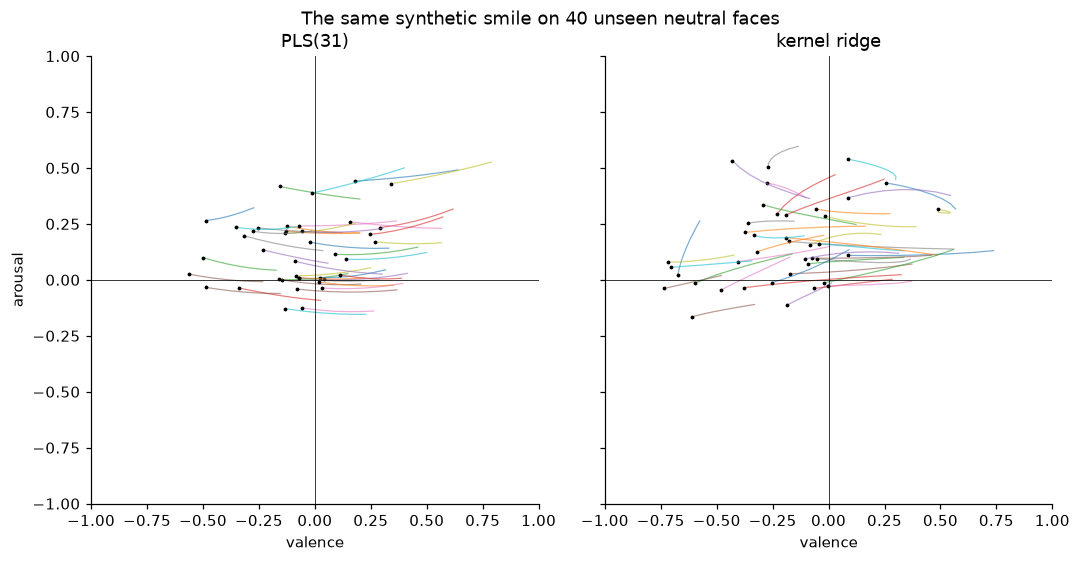

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
show = np.random.default_rng(0).choice(len(neutral), 40, replace=False)
for ax, (name, traj) in zip(axes, paths.items(), strict=True):
    for f in show:
        ax.plot(traj[:, f, 1], traj[:, f, 0], lw=0.8, alpha=0.6)
        ax.plot(traj[0, f, 1], traj[0, f, 0], "k.", ms=3)
    ax.axhline(0, c="k", lw=0.5)
    ax.axvline(0, c="k", lw=0.5)
    ax.set(xlim=(-1, 1), ylim=(-1, 1), aspect="equal", xlabel="valence", title=name)
axes[0].set_ylabel("arousal")
fig.suptitle("The same synthetic smile on 40 unseen neutral faces")
plt.tight_layout()

A linear model maps the same facial movement to the same output change for every face, so the
smile moves along the valence axis for everyone. The kernel model's response depends on how
close a face is to its training faces: on new identities, its trajectories bend and its resting
point drifts. PLS(31) wins all three tests. These are the properties a user sees live, so
**PLS(31) is the default** and kernel ridge is bundled as an alternative (better for extreme
expressions such as screams).

**Next:** notebook 04 retrains both final models and exports them.